In [1]:
## 1. Imports ##

In [2]:
import os
from dataclasses import dataclass, replace
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


## 2. Fixed Inputs ##

In [3]:
TRAIN_START = "2019-01-01"      # screening window -- candidate watchlists are compared using only this period
TRAIN_END = "2025-12-31"
BACKTEST_START = "2026-01-01"   # out-of-sample TEST window -- never used for screening, only for final validation
BACKTEST_END = "2026-09-01"

LOOKBACK_BUFFER_DAYS = 200       # extra calendar days fetched before TRAIN_START, purely to warm up momentum
INITIAL_CAPITAL = 5000           # used for standard CAGR/Sharpe comparison across candidates
TRANSACTION_COST_PCT = 0.0015    # T212 Invest/ISA: 0% commission + 0.15% FX conversion fee on every USD trade (GBP account)

BASE_CAPITAL = 1000              # pocket-money simulation base
MONTHLY_TARGET_GBP = 100         # pocket-money monthly withdrawal target


## 3. Strategy Parameters (Fixed at Best Tuned) ##

In [4]:
@dataclass
class StrategyParams:
    lookback: int = 63
    skip: int = 5
    min_lookback: int = 10
    top_n: int = 3
    rebalance_frequency: str = "weekly"
    stop_loss_pct: float | None = 0.10
    trailing_stop_pct: float | None = None
    profit_target_multiple: float | None = None
    require_positive_momentum: bool = True

BASELINE = StrategyParams()

# This script is NOT re-tuning parameters -- it holds the strategy fixed at the config validated
# out-of-sample in Backtest_1st_Paper_Trial.ipynb (Sections 15-16), and only varies the WATCHLIST.
FIXED_PARAMS = replace(BASELINE, stop_loss_pct=0.15, require_positive_momentum=False)


## 4. Candidate Watchlists ##

In [5]:
BENCHMARK = "SPY"

# Note: RIVN, LCID, COIN, and MARA (as a bitcoin miner) didn't exist or weren't relevant until
# 2021-ish -- the "EV & Semiconductors" and "Crypto-Adjacent" baskets will run more concentrated
# (fewer than 3 real candidates) for roughly the first 2 years of the TRAIN window. The engine
# handles this gracefully (excludes tickers with no data rather than crashing), but it means those
# baskets' early-period results are less representative than their post-2021 behavior.
CANDIDATE_WATCHLISTS = {
    "Original (current)": ["NVDA", "PATH", "INTC", "AAL", "TSLA", "AMC", "SMCI", "NIO", "NU"],
    "Big Tech High-Beta": ["NVDA", "AMD", "TSLA", "META", "AMZN", "MSTR", "COIN", "PLTR", "SMCI"],
    "EV & Semiconductors": ["TSLA", "RIVN", "LCID", "NVDA", "AMD", "SMCI", "MU", "ON", "MARA"],
    "Crypto-Adjacent & Speculative": ["COIN", "MARA", "RIOT", "MSTR", "PLTR", "SMCI", "NVDA", "TSLA", "SQ"],
    # Original with the 4 structurally weakest names (INTC, AAL, NIO, NU) swapped for clean
    # (non-crypto) candidates pulled from the other two baskets: AMD, META, PLTR, MU. This is a
    # targeted reshuffle, not a new theme -- it keeps NVDA/PATH/TSLA/AMC/SMCI unchanged.
    "Reshuffled (swap INTC/AAL/NIO/NU)": ["NVDA", "PATH", "TSLA", "AMC", "SMCI", "AMD", "META", "PLTR", "MU"],
}


## 5. Historical Data Loading (Per-Candidate) ##

In [6]:
def load_backtest_data(watchlist, start, end):
    data = {}
    for ticker in watchlist:
        df = yf.download(ticker, start=start, end=end, interval="1d", auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        data[ticker] = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    return data


fetch_start = (pd.Timestamp(TRAIN_START) - pd.Timedelta(days=LOOKBACK_BUFFER_DAYS)).strftime("%Y-%m-%d")

# Fetch each candidate's data once up front, keyed by candidate name, spanning buffer + TRAIN + TEST.
candidate_data = {}
for name, watchlist in CANDIDATE_WATCHLISTS.items():
    print(f"Fetching {name} ({len(watchlist)} tickers)...")
    candidate_data[name] = load_backtest_data(watchlist, fetch_start, BACKTEST_END)

benchmark_prices = load_backtest_data([BENCHMARK], fetch_start, BACKTEST_END)[BENCHMARK]
print("Done.")


Fetching Original (current) (9 tickers)...


Fetching Big Tech High-Beta (9 tickers)...


Fetching EV & Semiconductors (9 tickers)...


Fetching Crypto-Adjacent & Speculative (9 tickers)...


$SQ: possibly delisted; no timezone found



1 Failed download:


['SQ']: possibly delisted; no timezone found


Fetching Reshuffled (swap INTC/AAL/NIO/NU) (9 tickers)...


Done.


## 6. Momentum & Rebalance Schedule ##

In [7]:
def compute_rolling_momentum(price_series, lookback, skip):
    return price_series.shift(skip) / price_series.shift(skip + lookback) - 1

def get_rebalance_dates(index, frequency):
    if frequency == "none":
        dates = pd.DatetimeIndex([])
    elif frequency == "weekly":
        dates = index[index.weekday == 0]
    elif frequency == "biweekly":
        dates = index[index.weekday == 0][::2]
    elif frequency == "monthly":
        s = pd.Series(index, index=index)
        dates = pd.DatetimeIndex(s.groupby([index.year, index.month]).first().values)
    else:
        raise ValueError(f"unknown rebalance_frequency: {frequency}")

    if len(dates) == 0 or dates[0] != index[0]:
        dates = dates.insert(0, index[0])
    return pd.DatetimeIndex(dates)

def target_portfolio_at(momentum_scores, top_n, require_positive):
    ranked = momentum_scores.sort_values(ascending=False, na_position="last")
    top = ranked.head(top_n)
    if require_positive:
        top = top[top > 0]
    return list(top.index)


## 7. Backtest Engine ##

In [8]:
# Note: the profit-target mechanism from Backtest_1st_Paper_Trial.ipynb is omitted here since
# FIXED_PARAMS never uses it (profit_target_multiple stays None) -- everything else is identical
# to the validated engine.

def run_backtest(data, params: StrategyParams, initial_capital, transaction_cost_pct, sim_start=None, sim_end=None):
    all_dates = sorted(set().union(*[df.index for df in data.values()]))
    all_dates = pd.DatetimeIndex(all_dates)

    closes = pd.DataFrame({t: df["Close"] for t, df in data.items()}).reindex(all_dates).ffill()
    momentum = pd.DataFrame({
        t: compute_rolling_momentum(closes[t], params.lookback, params.skip)
        for t in closes.columns
    })

    sim_dates = closes.index
    if sim_start is not None:
        sim_dates = sim_dates[sim_dates >= pd.Timestamp(sim_start)]
    if sim_end is not None:
        sim_dates = sim_dates[sim_dates <= pd.Timestamp(sim_end)]
    rebalance_dates = set(get_rebalance_dates(sim_dates, params.rebalance_frequency))

    cash = initial_capital
    holdings = {}
    entry_prices = {}
    peak_prices = {}
    trade_log = []
    equity_records = [{"date": sim_dates[0] - pd.Timedelta(days=1), "equity": initial_capital}]

    def equity_now(prices_today):
        return cash + sum(holdings[t] * prices_today[t] for t in holdings if pd.notna(prices_today[t]))

    for date in sim_dates:
        prices_today = closes.loc[date]

        # update trailing peaks for every currently held position
        for ticker in holdings:
            price = prices_today[ticker]
            if pd.notna(price):
                peak_prices[ticker] = max(peak_prices.get(ticker, price), price)

        # 1a. per-position stop-loss (anchored to entry price)
        if params.stop_loss_pct is not None:
            for ticker in list(holdings.keys()):
                price = prices_today[ticker]
                entry = entry_prices[ticker]
                if pd.notna(price) and (entry - price) / entry >= params.stop_loss_pct:
                    qty = holdings.pop(ticker)
                    proceeds = qty * price * (1 - transaction_cost_pct)
                    cash += proceeds
                    entry_prices.pop(ticker, None)
                    peak_prices.pop(ticker, None)
                    trade_log.append({"date": date, "ticker": ticker, "side": "SELL (stop-loss)", "quantity": qty, "price": price, "equity": equity_now(prices_today)})

        # 1b. trailing stop (anchored to the peak price since entry)
        if params.trailing_stop_pct is not None:
            for ticker in list(holdings.keys()):
                price = prices_today[ticker]
                peak = peak_prices.get(ticker)
                if pd.notna(price) and peak and (peak - price) / peak >= params.trailing_stop_pct:
                    qty = holdings.pop(ticker)
                    proceeds = qty * price * (1 - transaction_cost_pct)
                    cash += proceeds
                    entry_prices.pop(ticker, None)
                    peak_prices.pop(ticker, None)
                    trade_log.append({"date": date, "ticker": ticker, "side": "SELL (trailing-stop)", "quantity": qty, "price": price, "equity": equity_now(prices_today)})

        # 2. rebalance
        if date in rebalance_dates:
            scores = momentum.loc[date]
            target = target_portfolio_at(scores, params.top_n, params.require_positive_momentum)

            for ticker in list(holdings.keys()):
                if ticker not in target:
                    price = prices_today[ticker]
                    qty = holdings.pop(ticker)
                    proceeds = qty * price * (1 - transaction_cost_pct)
                    cash += proceeds
                    entry_prices.pop(ticker, None)
                    peak_prices.pop(ticker, None)
                    trade_log.append({"date": date, "ticker": ticker, "side": "SELL (rebalance)", "quantity": qty, "price": price, "equity": equity_now(prices_today)})

            if target:
                alloc_base = equity_now(prices_today)
                weight = 1 / len(target)
                for ticker in target:
                    if ticker in holdings:
                        continue
                    price = prices_today[ticker]
                    if pd.isna(price):
                        continue
                    alloc = alloc_base * weight
                    shares = (alloc * (1 - transaction_cost_pct)) / price
                    holdings[ticker] = shares
                    entry_prices[ticker] = price
                    peak_prices[ticker] = price
                    cash -= alloc
                    trade_log.append({"date": date, "ticker": ticker, "side": "BUY", "quantity": shares, "price": price, "equity": equity_now(prices_today)})

        # 3. mark-to-market
        equity_records.append({"date": date, "equity": equity_now(prices_today)})

    equity_curve = pd.DataFrame(equity_records).set_index("date")
    equity_curve.attrs["turnover"] = len(trade_log)
    equity_curve.attrs["trades"] = trade_log
    return equity_curve


## 8. Performance Metrics & Visualization ##

In [9]:
def compute_metrics(equity_curve):
    equity = equity_curve["equity"]
    returns = equity.pct_change().dropna()

    years = len(equity) / 252
    cagr = (equity.iloc[-1] / equity.iloc[0]) ** (1 / years) - 1 if years > 0 else np.nan

    ann_vol = returns.std() * np.sqrt(252)
    sharpe = (returns.mean() * 252) / ann_vol if ann_vol > 0 else np.nan

    running_max = equity.cummax()
    drawdown = (equity - running_max) / running_max
    max_drawdown = drawdown.min()

    win_rate = (returns > 0).mean()
    turnover = equity_curve.attrs.get("turnover", np.nan)

    return {
        "cagr": cagr,
        "sharpe": sharpe,
        "max_drawdown": max_drawdown,
        "win_rate": win_rate,
        "turnover": turnover,
    }

COMPARISON_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]

def plot_equity_curves(curves, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = COMPARISON_COLORS[: len(curves)]

    for (label, curve), color in zip(curves.items(), colors):
        weekly = curve["equity"].resample("W").last().dropna()
        start_point = pd.Series([curve["equity"].iloc[0]], index=[curve.index[0]])
        weekly = pd.concat([start_point, weekly])
        ax.plot(weekly.index, weekly.values, label=label, color=color, linewidth=1.8, marker="o", markersize=3)

    ax.set_xlabel("Date")
    ax.set_ylabel("Equity (£)")
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

    locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.autofmt_xdate(rotation=30)
    fig.tight_layout()
    plt.show()

BACKTEST_TRADE_LOG_PATH = "Backtest_2nd_trade_log.xlsx"

def write_trades_sheet(sheet_name, curves):
    rows = []
    for variant_label, curve in curves.items():
        for trade in curve.attrs.get("trades", []):
            rows.append({"variant": variant_label, **trade})
    sheet_df = pd.DataFrame(rows)

    file_exists = os.path.exists(BACKTEST_TRADE_LOG_PATH)
    mode = "a" if file_exists else "w"
    kwargs = {"if_sheet_exists": "replace"} if file_exists else {}
    with pd.ExcelWriter(BACKTEST_TRADE_LOG_PATH, engine="openpyxl", mode=mode, **kwargs) as writer:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)


## 9. Pocket-Money Simulator (Floored £100/Month Design) ##

In [10]:
# The design validated in Backtest_1st_Paper_Trial.ipynb (Section 20) as the best of three tested:
# withdrawal is capped at the monthly target AND never allowed to push capital below the original
# base -- withdrawn = min(target, max(0, end_equity - base_capital)). Profit beyond base + target
# keeps compounding into next month's capital instead of being discarded.

def simulate_pocket_money_floored(data, params, base_capital, transaction_cost_pct, start, end, monthly_target_gbp):
    last_available_date = max(df.index.max() for df in data.values())

    month_starts = list(pd.date_range(start=start, end=end, freq="MS"))
    if pd.Timestamp(start) not in month_starts:
        month_starts.insert(0, pd.Timestamp(start))
    boundaries = month_starts + [pd.Timestamp(end) + pd.Timedelta(days=1)]

    current_capital = base_capital
    total_withdrawn = 0.0
    records = []

    for i in range(len(boundaries) - 1):
        p_start = boundaries[i]
        if p_start > last_available_date:
            break
        p_end = min(boundaries[i + 1] - pd.Timedelta(days=1), last_available_date)
        if p_start >= p_end:
            continue

        curve = run_backtest(data, params, current_capital, transaction_cost_pct, sim_start=p_start, sim_end=p_end)
        end_equity = curve["equity"].iloc[-1]

        withdrawable_room = max(0.0, end_equity - base_capital)
        withdrawn = min(monthly_target_gbp, withdrawable_room)
        total_withdrawn += withdrawn
        next_capital = end_equity - withdrawn

        records.append({
            "period_start": p_start.date(),
            "start_capital": current_capital,
            "end_equity": end_equity,
            "withdrawn": withdrawn,
            "total_withdrawn": total_withdrawn,
        })
        current_capital = next_capital

    results_df = pd.DataFrame(records)
    total_wealth = current_capital + total_withdrawn
    return results_df, current_capital, total_wealth


def summarize_pocket_money(results_df, final_capital, total_wealth, monthly_target_gbp):
    n_periods = len(results_df)
    n_full = (results_df["withdrawn"] >= monthly_target_gbp).sum()
    n_any = (results_df["withdrawn"] > 0).sum()
    return {
        "months": n_periods,
        "pct_full_hit": n_full / n_periods,
        "pct_partial": (n_any - n_full) / n_periods,
        "pct_zero": (n_periods - n_any) / n_periods,
        "avg_monthly_withdrawal": results_df["withdrawn"].mean(),
        "total_withdrawn": results_df["total_withdrawn"].iloc[-1],
        "final_capital": final_capital,
        "total_wealth": total_wealth,
    }


## 10. Stock Screen (Train): Standard Metrics + Pocket-Money Fit ##

=== Standard metrics (£5,000, fully compounded, Train) ===
                                       cagr    sharpe  max_drawdown  win_rate  turnover
candidate                                                                              
Original (current)                 0.676363  1.144795     -0.569541  0.526705       383
Big Tech High-Beta                 0.724767  1.204094     -0.708690  0.554545       383
EV & Semiconductors                0.685092  1.093418     -0.713448  0.532386       437
Crypto-Adjacent & Speculative      0.840400  1.141573     -0.816975  0.544886       381
Reshuffled (swap INTC/AAL/NIO/NU)  1.017430  1.427656     -0.627610  0.547727       393

=== Pocket-money fit (£1,000 base, £100/month target, Train) ===
                                   months  pct_full_hit  pct_partial  pct_zero  avg_monthly_withdrawal  total_withdrawn  final_capital  total_wealth
candidate                                                                                                     

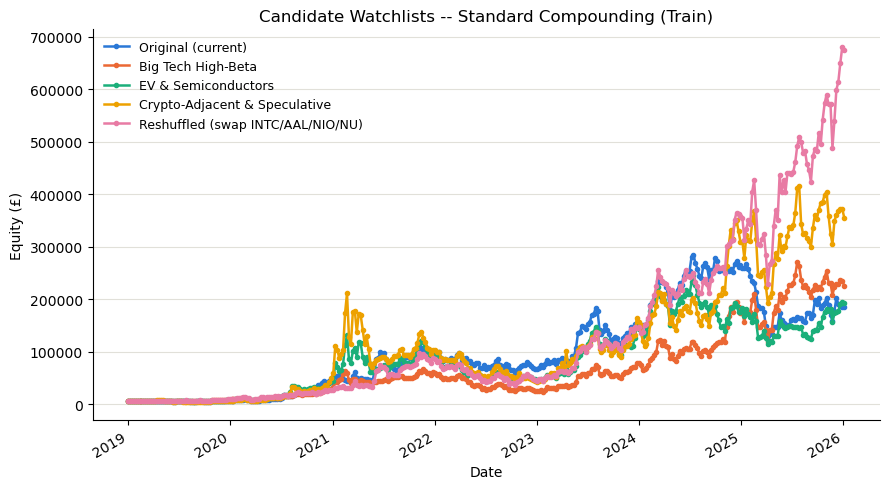

In [11]:
# For each candidate watchlist: run the standard (£5,000, no withdrawal) backtest for CAGR/Sharpe/
# drawdown context, AND run the floored £100/month pocket-money simulation on a £1,000 base --
# both evaluated ONLY on TRAIN_START..TRAIN_END, exactly the same discipline used for parameter
# tuning in Backtest_1st_Paper_Trial.ipynb. The winner gets validated out-of-sample in Section 11.

standard_rows = []
pocket_rows = []
standard_curves = {}

for name, cdata in candidate_data.items():
    std_curve = run_backtest(cdata, FIXED_PARAMS, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    standard_curves[name] = std_curve
    standard_rows.append({"candidate": name, **compute_metrics(std_curve)})

    pocket_df, pocket_final, pocket_wealth = simulate_pocket_money_floored(
        cdata, FIXED_PARAMS, BASE_CAPITAL, TRANSACTION_COST_PCT, TRAIN_START, TRAIN_END, MONTHLY_TARGET_GBP
    )
    pocket_rows.append({"candidate": name, **summarize_pocket_money(pocket_df, pocket_final, pocket_wealth, MONTHLY_TARGET_GBP)})

standard_results = pd.DataFrame(standard_rows).set_index("candidate")
pocket_results = pd.DataFrame(pocket_rows).set_index("candidate")

print("=== Standard metrics (£5,000, fully compounded, Train) ===")
print(standard_results.to_string())
print()
print("=== Pocket-money fit (£1,000 base, £100/month target, Train) ===")
print(pocket_results.to_string())
print()
best_candidate = pocket_results["total_wealth"].idxmax()
print(f"Best candidate by total wealth (pocket-money design): {best_candidate}")

plot_equity_curves(standard_curves, "Candidate Watchlists -- Standard Compounding (Train)")
write_trades_sheet("Standard Screen (Train)", standard_curves)


## 11. Out-of-Sample Validation (Test): All Candidates vs S&P 500 ##

Out-of-sample results (2026-01-01 to 2026-09-01, never used for screening):

=== Standard metrics ===
                                       cagr    sharpe  max_drawdown  win_rate  turnover
Original (current)                 0.723661  1.175559     -0.340871  0.512048        41
Big Tech High-Beta                 0.307938  0.758739     -0.300087  0.530120        69
EV & Semiconductors                1.976792  1.892602     -0.369669  0.584337        33
Crypto-Adjacent & Speculative     -0.273365 -0.135369     -0.473428  0.506024        45
Reshuffled (swap INTC/AAL/NIO/NU)  2.800631  2.356524     -0.289697  0.572289        35
Buy & hold S&P 500                 0.197799  1.416598     -0.088850  0.524096         1

=== Pocket-money fit ===
                                   months  pct_full_hit  pct_partial  pct_zero  avg_monthly_withdrawal  total_withdrawn  final_capital  total_wealth
candidate                                                                                                  

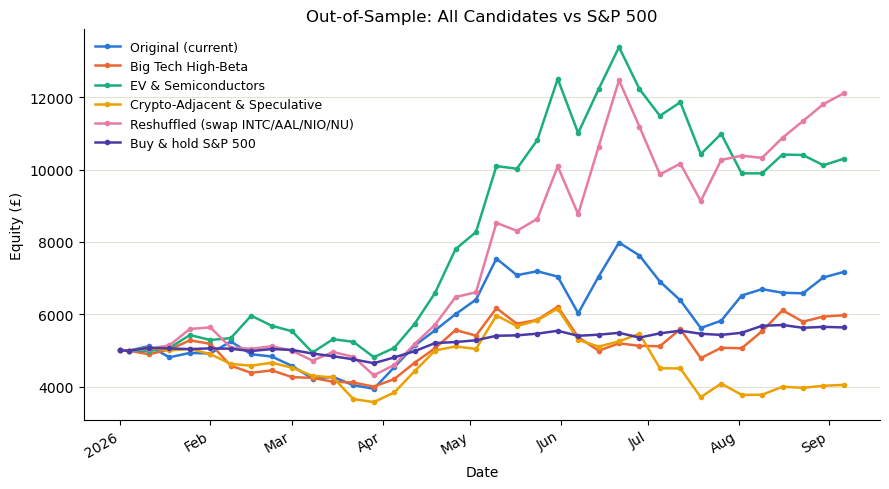

In [12]:
# Genuine out-of-sample check: evaluates ALL FOUR candidates fresh on 2026 -- data the Section 10
# screen never saw -- not just the training-set "winner", so we can see whether Big Tech High-Beta
# or EV & Semiconductors generalize any better than Crypto-Adjacent did.

test_standard_curves = {}
test_pocket_summaries = []

for name, cdata in candidate_data.items():
    std_curve = run_backtest(cdata, FIXED_PARAMS, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=BACKTEST_START, sim_end=BACKTEST_END)
    test_standard_curves[name] = std_curve

    pocket_df, pocket_final, pocket_wealth = simulate_pocket_money_floored(
        cdata, FIXED_PARAMS, BASE_CAPITAL, TRANSACTION_COST_PCT, BACKTEST_START, BACKTEST_END, MONTHLY_TARGET_GBP
    )
    test_pocket_summaries.append({"candidate": name, **summarize_pocket_money(pocket_df, pocket_final, pocket_wealth, MONTHLY_TARGET_GBP)})

spy_params = replace(FIXED_PARAMS, top_n=1, require_positive_momentum=False, rebalance_frequency="none")
spy_curve = run_backtest({BENCHMARK: benchmark_prices}, spy_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=BACKTEST_START, sim_end=BACKTEST_END)
test_standard_curves["Buy & hold S&P 500"] = spy_curve

test_standard_results = pd.DataFrame(
    [compute_metrics(c) for c in test_standard_curves.values()], index=list(test_standard_curves.keys())
)
test_pocket_results = pd.DataFrame(test_pocket_summaries).set_index("candidate")

print(f"Out-of-sample results ({BACKTEST_START} to {BACKTEST_END}, never used for screening):")
print()
print("=== Standard metrics ===")
print(test_standard_results.to_string())
print()
print("=== Pocket-money fit ===")
print(test_pocket_results.to_string())

plot_equity_curves(test_standard_curves, "Out-of-Sample: All Candidates vs S&P 500")
write_trades_sheet("OOS Validation (Test)", test_standard_curves)


## 12. Combined Trade Log (Data Wrangler) ##

In [13]:
all_sheets = pd.read_excel(BACKTEST_TRADE_LOG_PATH, sheet_name=None)
combined_trades = pd.concat(
    [df.assign(experiment=sheet_name) for sheet_name, df in all_sheets.items()],
    ignore_index=True,
)
combined_trades


,variant,date,ticker,side,quantity,price,equity,experiment
0,Original (current),2019-01-02,TSLA,BUY,80.493032,20.674667,4997.500000,Standard Screen (Train)
1,Original (current),2019-01-02,INTC,BUY,41.072237,40.518044,4995.000000,Standard Screen (Train)
2,Original (current),2019-01-02,NIO,BUY,268.413987,6.200000,4992.500000,Standard Screen (Train)
3,Original (current),2019-01-14,INTC,SELL (rebalance),41.072237,41.611031,5326.167640,Standard Screen (Train)
4,Original (current),2019-01-14,SMCI,BUY,1155.623262,1.534000,5323.504557,Standard Screen (Train)
...,...,...,...,...,...,...,...,...
2196,Reshuffled (swap INTC/AAL/NIO/NU),2026-08-24,PLTR,SELL (rebalance),21.058783,175.889999,11502.256774,OOS Validation (Test)
2197,Reshuffled (swap INTC/AAL/NIO/NU),2026-08-24,MU,BUY,4.204974,910.429993,11496.505646,OOS Validation (Test)
2198,Reshuffled (swap INTC/AAL/NIO/NU),2026-08-31,MU,SELL (rebalance),4.204974,958.729980,12118.718221,OOS Validation (Test)
2199,Reshuffled (swap INTC/AAL/NIO/NU),2026-08-31,PLTR,BUY,21.641342,186.380005,12112.658861,OOS Validation (Test)
